In [1]:
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt

In [2]:
def compare_means(x, y, alpha=0.05, known_vars=None, equal_var=False):
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)

    n1, n2 = len(x), len(y)
    mean_diff = x.mean() - y.mean()

    if known_vars is not None:
        var1, var2 = known_vars
        statistic = mean_diff / np.sqrt(
            var1 / n1 + var2 / n2
        )
        p_value = 2 * stats.norm.sf(abs(statistic))
        test_name = "Z-test"
    else:
        result = stats.ttest_ind(x, y, equal_var=equal_var)
        statistic = result.statistic
        p_value = result.pvalue
        test_name = "Student t-test"

    return {
        "test": test_name,
        "mean_x": x.mean(),
        "mean_y": y.mean(),
        "difference": mean_diff,
        "statistic": statistic,
        "p_value": p_value,
        "reject_h0": p_value < alpha
    }

In [3]:
def get_cases():
    return [
        {
            "name": "Z-test: известные дисперсии",
            "mu1": 10, "mu2": 10,
            "sigma1": 2, "sigma2": 2,
            "known_vars": (4, 4),
        },
        {
            "name": "Z-test: известные дисперсии, разные средние",
            "mu1": 10, "mu2": 11,
            "sigma1": 2, "sigma2": 2,
            "known_vars": (4, 4),
        },
        {
            "name": "Student t-test: неизвестные равные дисперсии",
            "mu1": 10, "mu2": 10,
            "sigma1": 2, "sigma2": 2,
            "known_vars": None,
        },
        {
            "name": "Student t-test: неизвестные равные дисперсии, разные средние",
            "mu1": 10, "mu2": 11,
            "sigma1": 2, "sigma2": 2,
            "known_vars": None,
        },
    ]

In [4]:
def run_experiments():
    sample_sizes = [10, 100, 1000, 10000]
    alpha = 0.05
    cases = get_cases()

    for case_index, case in enumerate(cases):
        print("\n" + "=" * 105)
        print(case["name"])
        print(
            f"mu1={case["mu1"]}, mu2={case["mu2"]}, "
            f"sigma1={case["sigma1"]}, sigma2={case["sigma2"]}"
        )
        print("-" * 105)
        print(
            f"{"n":>7} {"mean_x":>12} {"mean_y":>12} "
            f"{"difference":>12} {"statistic":>12} "
            f"{"p-value":>14} {"decision":^20}"
        )
        print("-" * 105)

        for n in sample_sizes:
            rng = np.random.default_rng(
                1000 * (case_index + 1) + n
            )

            x = rng.normal(case["mu1"], case["sigma1"], n)
            y = rng.normal(case["mu2"], case["sigma2"], n)

            result = compare_means(
                x, y,
                alpha=alpha,
                known_vars=case["known_vars"],
                equal_var=True
            )

            decision = (
                "Отвергаем H0"
                if result["reject_h0"]
                else "Не отвергаем H0"
            )

            print(
                f"{n:7d} "
                f"{result["mean_x"]:12.4f} "
                f"{result["mean_y"]:12.4f} "
                f"{result["difference"]:12.4f} "
                f"{result["statistic"]:12.4f} "
                f"{result["p_value"]:14.6g} "
                f"{decision:^20}"
            )

        print("-" * 105)

In [5]:
def plot_statistic_distributions():
    sample_sizes = [10, 100, 1000, 10000]
    repetitions = 5000
    cases = get_cases()

    for case_index, case in enumerate(cases):
        fig, axes = plt.subplots(
            2, 2, figsize=(12, 8),
            constrained_layout=True
        )
        fig.suptitle(case["name"])

        for ax, n in zip(axes.flat, sample_sizes):
            rng = np.random.default_rng(
                1000 * (case_index + 1) + n
            )

            x = rng.normal(
                case["mu1"], case["sigma1"],
                size=(repetitions, n)
            )
            y = rng.normal(
                case["mu2"], case["sigma2"],
                size=(repetitions, n)
            )

            mean_diff = x.mean(axis=1) - y.mean(axis=1)

            if case["known_vars"] is not None:
                var1, var2 = case["known_vars"]
                se = np.sqrt(var1 / n + var2 / n)
                statistic = mean_diff / se
                grid = np.linspace(
                    statistic.min(), statistic.max(), 500
                )

                ax.plot(
                    grid, stats.norm.pdf(grid),
                    linestyle="--",
                    label="N(0, 1) при H0"
                )
                statistic_name = "Z"

            else:
                var_x = x.var(axis=1, ddof=1)
                var_y = y.var(axis=1, ddof=1)

                pooled_var = (
                    (n - 1) * var_x + (n - 1) * var_y
                ) / (2 * n - 2)

                statistic = mean_diff / np.sqrt(
                    pooled_var * (2 / n)
                )

                grid = np.linspace(
                    statistic.min(), statistic.max(), 500
                )

                ax.plot(
                    grid, stats.t.pdf(grid, 2 * n - 2),
                    linestyle="--",
                    label="t-распределение при H0"
                )
                statistic_name = "t"

            ax.hist(
                statistic,
                bins=50,
                density=True,
                alpha=0.65,
                label="Эмпирическое распределение"
            )

            ax.axvline(0, linestyle=":", color="black")
            ax.set_title(f"n = {n}")
            ax.set_xlabel(f"Статистика {statistic_name}")
            ax.set_ylabel("Плотность")
            ax.legend(fontsize=8)
            ax.grid(alpha=0.2)

        plt.show()


Z-test: известные дисперсии
mu1=10, mu2=10, sigma1=2, sigma2=2
---------------------------------------------------------------------------------------------------------
      n       mean_x       mean_y   difference    statistic        p-value       decision      
---------------------------------------------------------------------------------------------------------
     10       9.4910      10.3031      -0.8121      -0.9079       0.363917   Не отвергаем H0   
    100       9.9903      10.0482      -0.0579      -0.2046       0.837895   Не отвергаем H0   
   1000       9.9275      10.1062      -0.1787      -1.9981      0.0457047     Отвергаем H0    
  10000      10.0172      10.0162       0.0010       0.0350       0.972081   Не отвергаем H0   
---------------------------------------------------------------------------------------------------------

Z-test: известные дисперсии, разные средние
mu1=10, mu2=11, sigma1=2, sigma2=2
----------------------------------------------------------

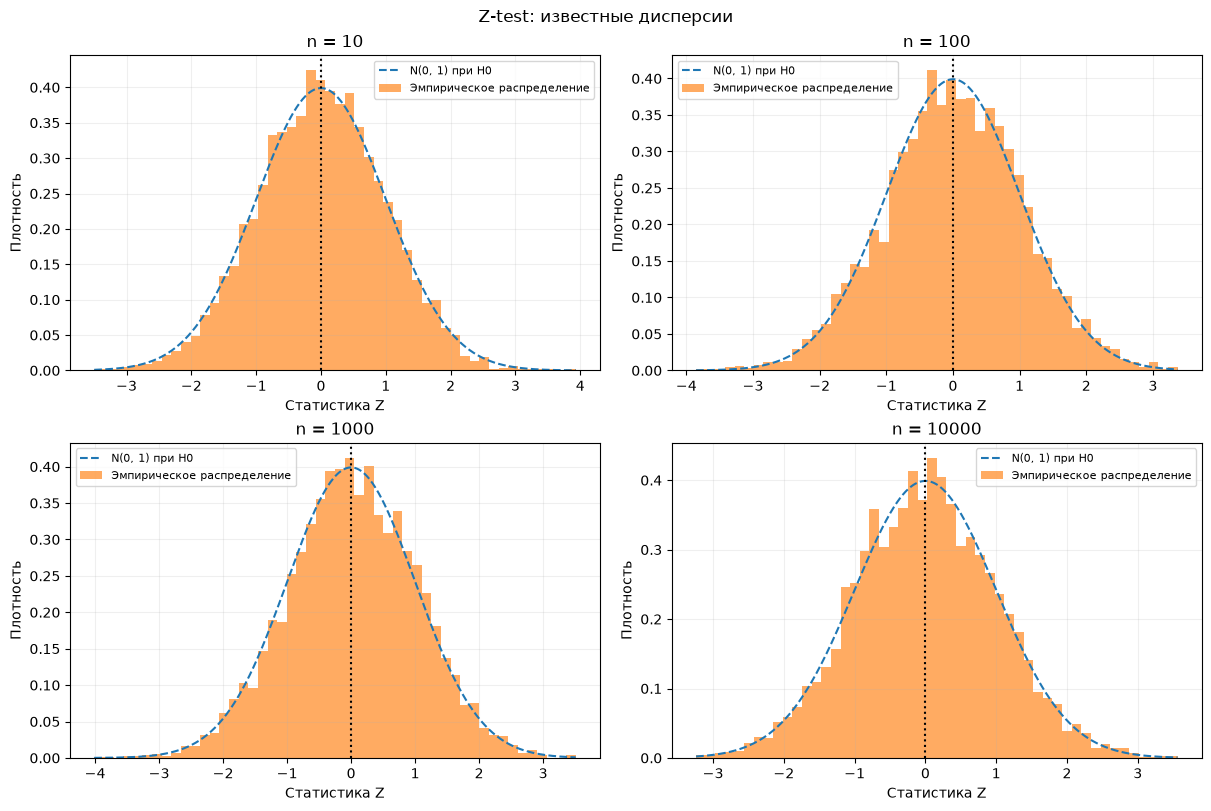

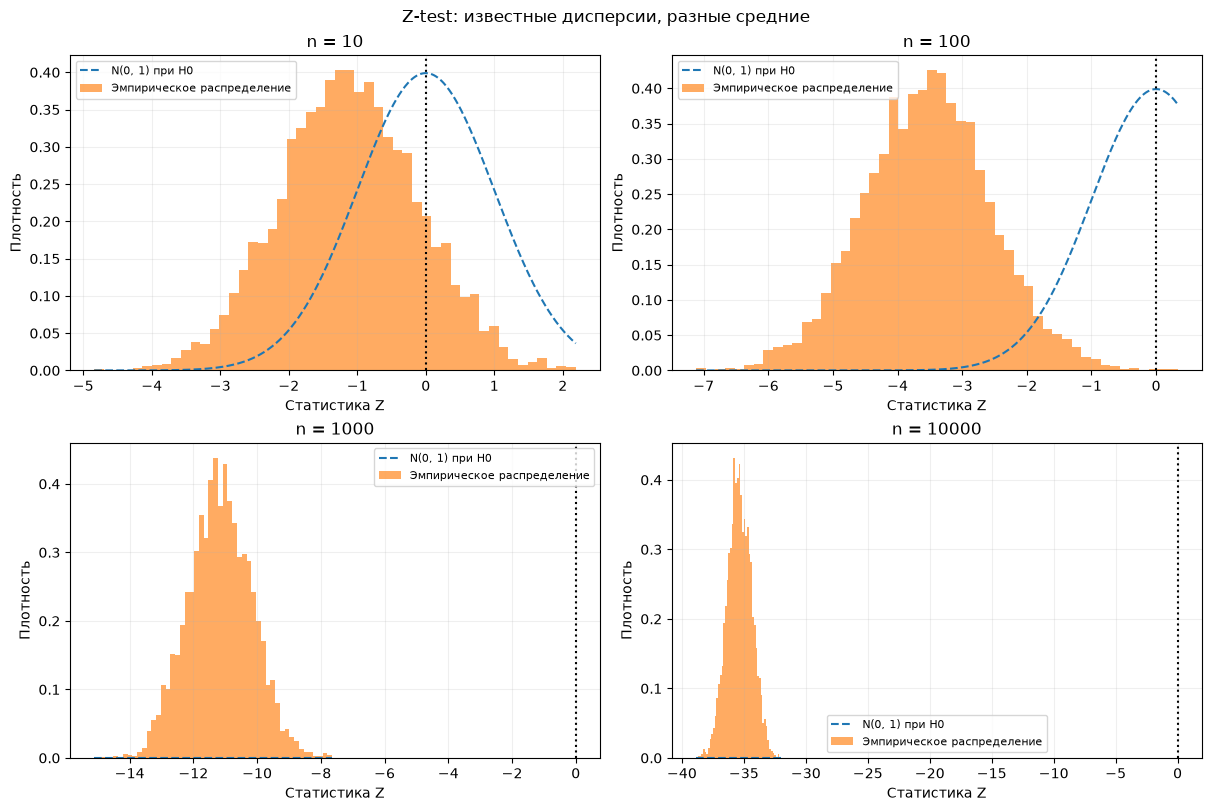

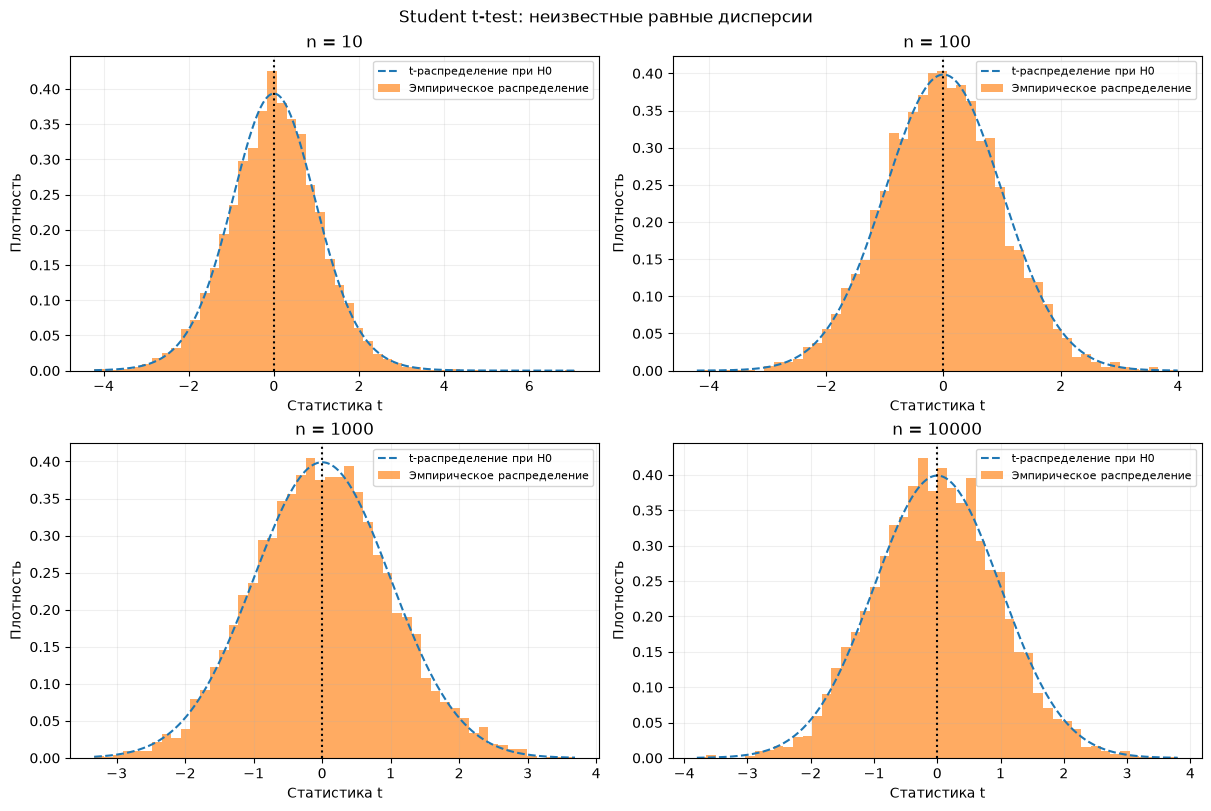

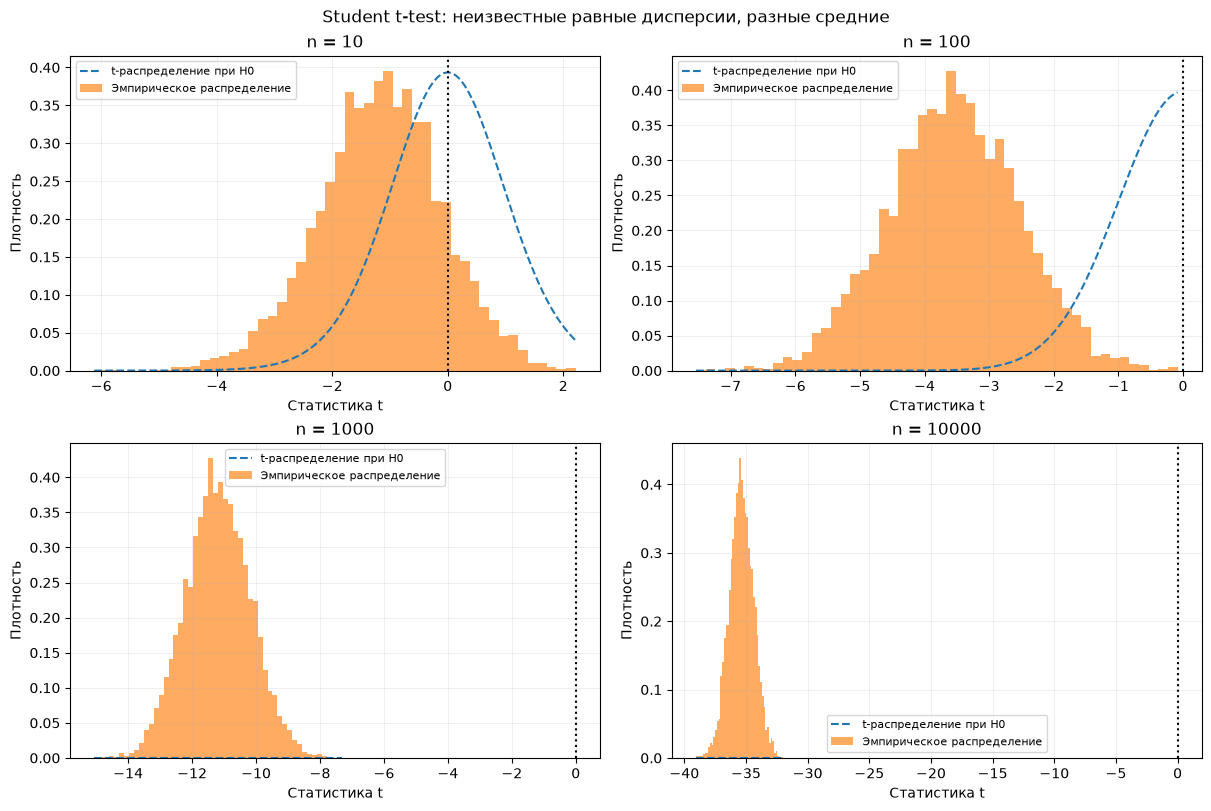

In [6]:
run_experiments()
plot_statistic_distributions()

In [7]:
def compare_variances(x, y, alpha=0.05):
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)

    n1, n2 = len(x), len(y)
    var_x = np.var(x, ddof=1)
    var_y = np.var(y, ddof=1)

    if var_x > var_y:
        statistic = var_x / var_y
        df1, df2 = n1 - 1, n2 - 1
    else:
        statistic = var_y / var_x
        df1, df2 = n2 - 1, n1 - 1

    p_value = 2 * stats.f.sf(statistic, df1, df2)
    p_value = min(p_value, 1.0)

    return {
        "test": "Fisher F-test",
        "var_x": var_x,
        "var_y": var_y,
        "ratio": statistic,
        "df1": df1,
        "df2": df2,
        "p_value": p_value,
        "reject_h0": p_value < alpha
    }

In [8]:
def get_cases():
    return [
        {
            "name": "F-test: равные дисперсии",
            "mu1": 10, "mu2": 10,
            "sigma1": 2, "sigma2": 2,
        },
        {
            "name": "F-test: разные дисперсии (sigma1 < sigma2)",
            "mu1": 10, "mu2": 10,
            "sigma1": 2, "sigma2": 3,
        },
        {
            "name": "F-test: разные дисперсии (sigma1 > sigma2)",
            "mu1": 10, "mu2": 10,
            "sigma1": 4, "sigma2": 1,
        }
    ]

In [9]:
def run_experiments():
    sample_sizes = [10, 100, 1000, 10000]
    alpha = 0.05
    cases = get_cases()

    for case_index, case in enumerate(cases):
        print("\n" + "=" * 115)
        print(case["name"])
        print(
            f"mu1={case["mu1"]}, mu2={case["mu2"]}, "
            f"sigma1={case["sigma1"]}, sigma2={case["sigma2"]}"
        )
        print("-" * 115)
        print(
            f"{"n":>7} {"var_x":>12} {"var_y":>12} "
            f"{"ratio":>12} {"df1":>6} {"df2":>6} "
            f"{"p-value":>14} {"decision":^20}"
        )
        print("-" * 115)

        for n in sample_sizes:
            rng = np.random.default_rng(
                1000 * (case_index + 1) + n
            )

            x = rng.normal(case["mu1"], case["sigma1"], n)
            y = rng.normal(case["mu2"], case["sigma2"], n)

            result = compare_variances(
                x, y,
                alpha=alpha
            )

            decision = (
                "Отвергаем H0"
                if result["reject_h0"]
                else "Не отвергаем H0"
            )

            print(
                f"{n:7d} "
                f"{result["var_x"]:12.4f} "
                f"{result["var_y"]:12.4f} "
                f"{result["ratio"]:12.4f} "
                f"{result["df1"]:6d} "
                f"{result["df2"]:6d} "
                f"{result["p_value"]:14.6g} "
                f"{decision:^20}"
            )

        print("-" * 115)

In [10]:
def plot_statistic_distributions():
    sample_sizes = [10, 100, 1000, 10000]
    repetitions = 5000
    cases = get_cases()

    for case_index, case in enumerate(cases):
        fig, axes = plt.subplots(
            2, 2, figsize=(12, 8),
            constrained_layout=True
        )
        fig.suptitle(case["name"])

        for ax, n in zip(axes.flat, sample_sizes):
            rng = np.random.default_rng(
                1000 * (case_index + 1) + n
            )

            x = rng.normal(
                case["mu1"], case["sigma1"],
                size=(repetitions, n)
            )
            y = rng.normal(
                case["mu2"], case["sigma2"],
                size=(repetitions, n)
            )

            var_x = x.var(axis=1, ddof=1)
            var_y = y.var(axis=1, ddof=1)

            statistic = var_x / var_y

            grid = np.linspace(0, max(statistic.max(), 5), 500)

            ax.plot(
                grid, stats.f.pdf(grid, n - 1, n - 1),
                linestyle="--",
                label="F-распределение при H0"
            )

            ax.hist(
                statistic,
                bins=100,
                density=True,
                alpha=0.65,
                label="Эмпирическое распределение"
            )

            ax.axvline(1.0, linestyle=":", color="black")
            ax.set_title(f"n = {n}")
            ax.set_xlabel("Статистика F = S1^2 / S2^2")
            ax.set_ylabel("Плотность")
            ax.set_xlim(0, 5) # Ограничиваем x для наглядности
            ax.legend(fontsize=8)
            ax.grid(alpha=0.2)

        plt.show()


F-test: равные дисперсии
mu1=10, mu2=10, sigma1=2, sigma2=2
-------------------------------------------------------------------------------------------------------------------
      n        var_x        var_y        ratio    df1    df2        p-value       decision      
-------------------------------------------------------------------------------------------------------------------
     10       4.2852       5.5902       1.3045      9      9       0.698512   Не отвергаем H0   
    100       3.3488       3.5258       1.0529     99     99       0.798292   Не отвергаем H0   
   1000       3.9500       3.9807       1.0078    999    999       0.902747   Не отвергаем H0   
  10000       4.1080       3.9844       1.0310   9999   9999       0.126856   Не отвергаем H0   
-------------------------------------------------------------------------------------------------------------------

F-test: разные дисперсии (sigma1 < sigma2)
mu1=10, mu2=10, sigma1=2, sigma2=3
---------------------------

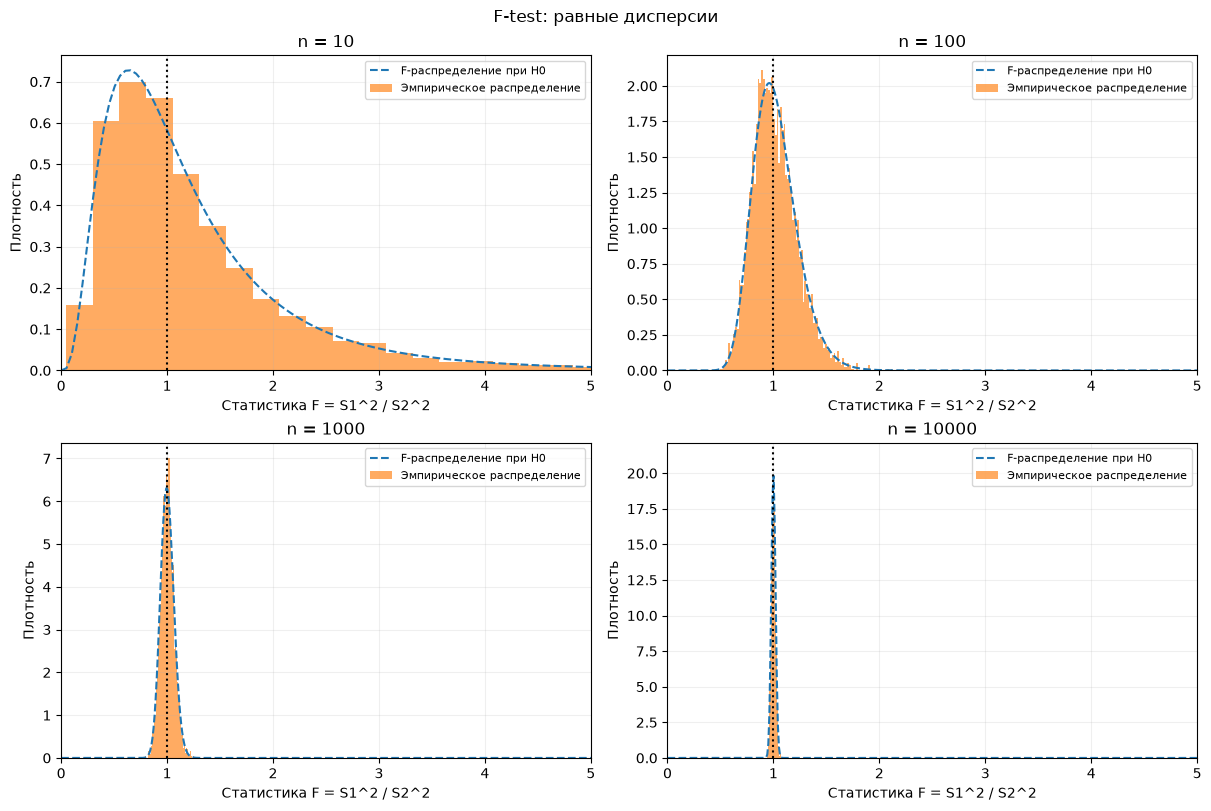

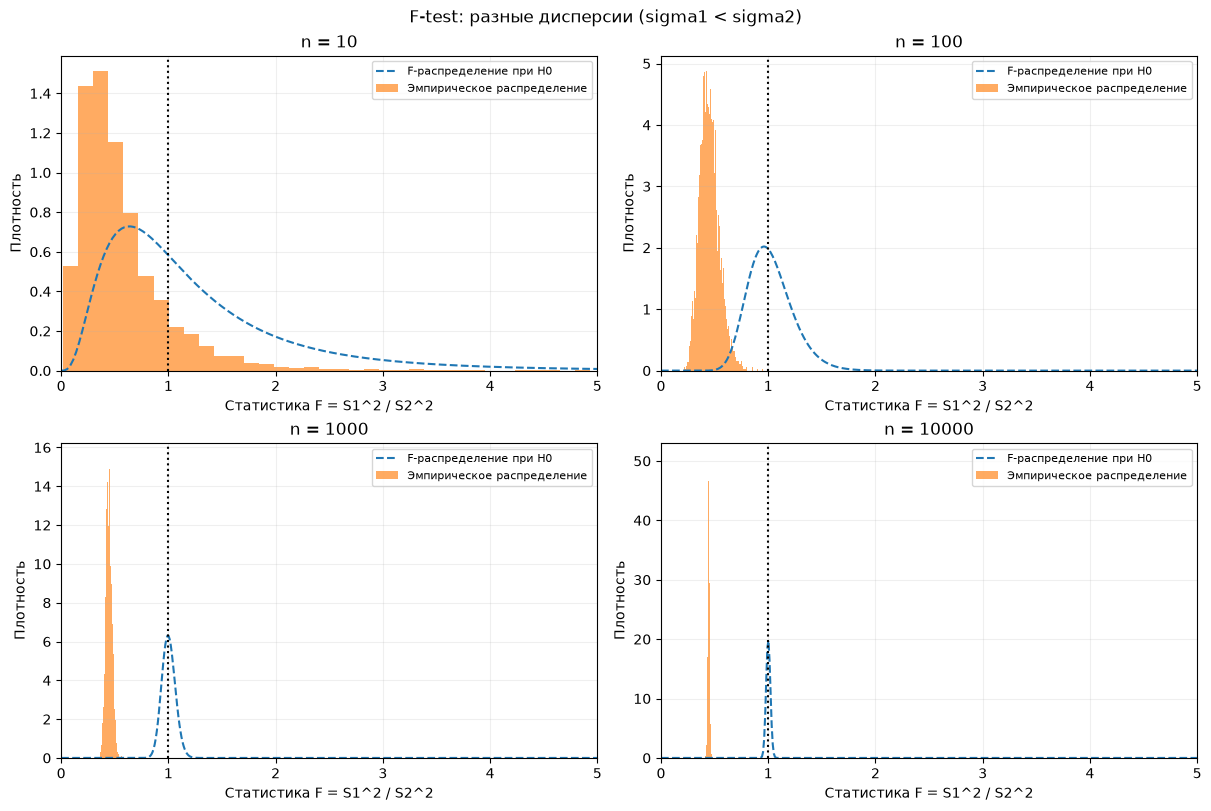

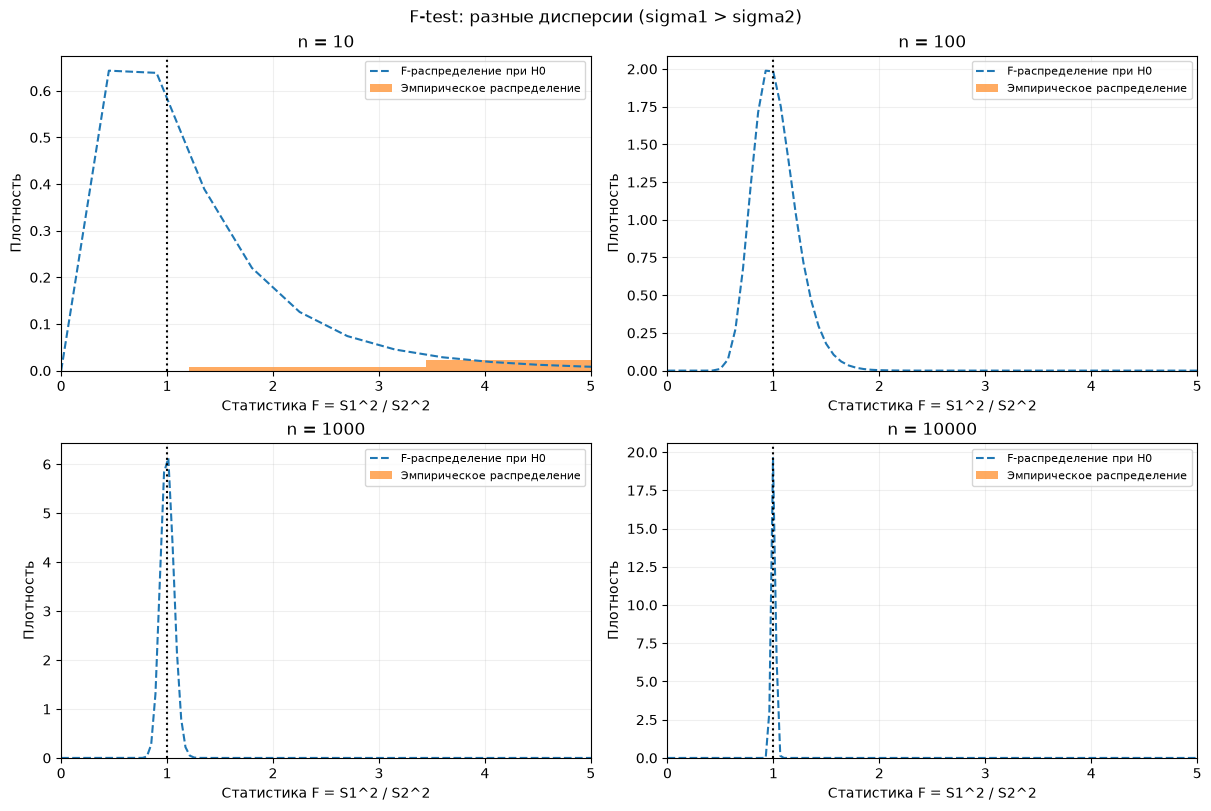

In [11]:
run_experiments()
plot_statistic_distributions()

In [12]:
import pandas as pd

np.random.seed(42)
n = 200
alpha = 0.05

true_mu, true_sigma = 5.0, 2.0
sample_norm = np.random.normal(loc=true_mu, scale=true_sigma, size=n)

true_scale = 2.0 
sample_exp = np.random.exponential(scale=true_scale, size=n)

In [13]:
def pearson_continuous(data, dist, k, r=0):
    edges = [dist.ppf(i/k) for i in range(1, k)]
    edges = [-np.inf] + edges + [np.inf]
    O, _ = np.histogram(data, bins=edges)
    E = np.full(k, len(data) / k)
    chi2 = np.sum((O - E)**2 / E)
    df = k - 1 - r
    return chi2, stats.chi2.ppf(1 - alpha, df)

In [14]:
def ks_test_simple(data, dist):
    D, _ = stats.kstest(data, dist.cdf)
    crit = stats.kstwo.ppf(1 - alpha, len(data))
    return D, crit

In [15]:
def ks_test_complex_bootstrap(data, dist_name, n_boot=1000):
    dist = getattr(stats, dist_name)
    params = dist.fit(data)
    D_obs, _ = stats.kstest(data, lambda x: dist.cdf(x, *params))
    
    rng = np.random.default_rng(123)
    D_boot = []
    for _ in range(n_boot):
        sim_data = dist.rvs(*params, size=len(data), random_state=rng)
        sim_params = dist.fit(sim_data)
        D_sim, _ = stats.kstest(sim_data, lambda x: dist.cdf(x, *sim_params))
        D_boot.append(D_sim)
        
    return D_obs, np.percentile(D_boot, 95)

In [16]:
def get_decision(stat, crit):
    return "H0 не отвергается" if stat < crit else "H0 отвергается"

rows = []
k_bins = 10

In [17]:
dist_norm_s = stats.norm(loc=true_mu, scale=true_sigma)
chi2_s, crit_chi2_s = pearson_continuous(sample_norm, dist_norm_s, k_bins, r=0)
ks_s, crit_ks_s = ks_test_simple(sample_norm, dist_norm_s)
rows.append(["Пирсон", f"простая, N({true_mu}, {true_sigma})", f"X² = {chi2_s:.4f}", f"{crit_chi2_s:.4f}", get_decision(chi2_s, crit_chi2_s)])
rows.append(["Колмогоров", f"простая, N({true_mu}, {true_sigma})", f"K = {ks_s:.4f}", f"{crit_ks_s:.4f}", get_decision(ks_s, crit_ks_s)])

In [18]:
fit_mu_n, fit_sigma_n = stats.norm.fit(sample_norm)
dist_norm_c = stats.norm(loc=fit_mu_n, scale=fit_sigma_n)
chi2_c, crit_chi2_c = pearson_continuous(sample_norm, dist_norm_c, k_bins, r=2)
ks_c, crit_ks_c = ks_test_complex_bootstrap(sample_norm, "norm")
rows.append(["Пирсон", f"сложная, N({fit_mu_n:.4f}, {fit_sigma_n:.4f})", f"X² = {chi2_c:.4f}", f"{crit_chi2_c:.4f}", get_decision(chi2_c, crit_chi2_c)])
rows.append(["Колмогоров", f"сложная, N({fit_mu_n:.4f}, {fit_sigma_n:.4f})", f"K = {ks_c:.4f}", f"{crit_ks_c:.4f}", get_decision(ks_c, crit_ks_c)])

In [19]:
dist_exp_s = stats.expon(scale=true_scale)
chi2_s_e, crit_chi2_s_e = pearson_continuous(sample_exp, dist_exp_s, k_bins, r=0)
ks_s_e, crit_ks_s_e = ks_test_simple(sample_exp, dist_exp_s)
rows.append(["Пирсон", f"простая, Exp({true_scale})", f"X² = {chi2_s_e:.4f}", f"{crit_chi2_s_e:.4f}", get_decision(chi2_s_e, crit_chi2_s_e)])
rows.append(["Колмогоров", f"простая, Exp({true_scale})", f"K = {ks_s_e:.4f}", f"{crit_ks_s_e:.4f}", get_decision(ks_s_e, crit_ks_s_e)])

In [20]:
fit_loc_e, fit_scale_e = stats.expon.fit(sample_exp)
dist_exp_c = stats.expon(loc=fit_loc_e, scale=fit_scale_e)
fit_scale_e_only = np.mean(sample_exp)
dist_exp_c_only = stats.expon(scale=fit_scale_e_only)

chi2_c_e, crit_chi2_c_e = pearson_continuous(sample_exp, dist_exp_c_only, k_bins, r=1)
ks_c_e, crit_ks_c_e = ks_test_complex_bootstrap(sample_exp, "expon")

In [21]:
rows.append(["Пирсон", f"сложная, Exp({fit_scale_e_only:.4f})", f"X² = {chi2_c_e:.4f}", f"{crit_chi2_c_e:.4f}", get_decision(chi2_c_e, crit_chi2_c_e)])
rows.append(["Колмогоров", f"сложная, Exp({fit_scale_e_only:.4f})", f"K = {ks_c_e:.4f}", f"{crit_ks_c_e:.4f}", get_decision(ks_c_e, crit_ks_c_e)])

In [22]:
pd.DataFrame(rows, columns=["Критерий", "Гипотеза", "Статистика", "Критическое значение", "Решение"])

,Критерий,Гипотеза,Статистика,Критическое значение,Решение
0,Пирсон,"простая, N(5.0, 2.0)",X² = 9.5000,16.9190,H0 не отвергается
1,Колмогоров,"простая, N(5.0, 2.0)",K = 0.0650,0.0952,H0 не отвергается
2,Пирсон,"сложная, N(4.9185, 1.8573)",X² = 6.3000,14.0671,H0 не отвергается
3,Колмогоров,"сложная, N(4.9185, 1.8573)",K = 0.0382,0.0631,H0 не отвергается
4,Пирсон,"простая, Exp(2.0)",X² = 14.0000,16.9190,H0 не отвергается
5,Колмогоров,"простая, Exp(2.0)",K = 0.0812,0.0952,H0 не отвергается
6,Пирсон,"сложная, Exp(1.9334)",X² = 15.0000,15.5073,H0 не отвергается
7,Колмогоров,"сложная, Exp(1.9334)",K = 0.0861,0.0762,H0 отвергается


In [23]:
from scipy.stats import kstest, kstwobign, gamma, lognorm, norm

In [24]:
N = 1000
n = 100
ALPHA = 0.05
MU = 0.0
SIGMA = 1.0
M = 10

rng = np.random.default_rng(42)

In [25]:
def pearson_normal(x, fitted=False):
    if fitted:
        mu = np.mean(x)
        sigma = np.std(x, ddof=0)
        df = M - 3
    else:
        mu = MU
        sigma = SIGMA
        df = M - 1

    edges = stats.norm.ppf(
        np.linspace(0, 1, M + 1),
        loc=mu,
        scale=sigma
    )
    edges[0] = -np.inf
    edges[-1] = np.inf

    observed, _ = np.histogram(x, bins=edges)
    expected = np.full(M, len(x) / M)

    statistic = np.sum((observed - expected) ** 2 / expected)
    pvalue = stats.chi2.sf(statistic, df)

    return statistic, pvalue, df

In [26]:
def pearson_gof(sample, cdf, bins=10):
    sample = np.asarray(sample)

    lo = np.min(sample) - 10 * np.std(sample) - 1
    hi = np.max(sample) + 10 * np.std(sample) + 1

    grid = np.linspace(lo, hi, 50001)
    values = np.clip(cdf(grid), 0, 1)
    values = np.maximum.accumulate(values)

    edges = [-np.inf]

    for q in np.linspace(0, 1, bins + 1)[1:-1]:
        j = np.searchsorted(values, q)
        j = np.clip(j, 1, len(grid) - 1)

        x0, x1 = grid[j - 1], grid[j]
        f0, f1 = values[j - 1], values[j]

        if f1 > f0:
            edge = x0 + (q - f0) * (x1 - x0) / (f1 - f0)
        else:
            edge = grid[j]

        edges.append(edge)

    edges.append(np.inf)

    observed, _ = np.histogram(sample, bins=edges)
    expected = np.full(bins, len(sample) / bins)

    statistic = np.sum((observed - expected) ** 2 / expected)
    df = bins - 1
    pvalue = stats.chi2.sf(statistic, df)

    return statistic, pvalue, df


In [27]:
def ks_distance(sample, cdf):
    x = np.sort(np.asarray(sample))
    N = len(x)

    F = np.asarray(cdf(x))
    i = np.arange(1, N + 1)

    d_plus = np.max(i / N - F)
    d_minus = np.max(F - (i - 1) / N)

    return max(d_plus, d_minus)

In [28]:
simple_rows = []
complex_rows = []

D_simple = []
D_complex = []
X2_simple = []
X2_complex = []

for i in range(N):
    x = rng.normal(MU, SIGMA, n)

    # Простая гипотеза: параметры известны
    ks = stats.kstest(
        x,
        stats.norm(loc=MU, scale=SIGMA).cdf,
        method="exact"
    )

    x2, p2, _ = pearson_normal(x, fitted=False)

    D_simple.append(ks.statistic)
    X2_simple.append(x2)

    simple_rows.append({
        "Выборка": i + 1,
        "D_n": ks.statistic,
        "p Колмогорова": ks.pvalue,
        "Chi2": x2,
        "p Chi2": p2,
        "Решение KS": (
            "Не отвергаем H0" if ks.pvalue >= ALPHA
            else "Отвергаем H0"
        ),
        "Решение Chi2": (
            "Не отвергаем H0" if p2 >= ALPHA
            else "Отвергаем H0"
        )
    })

    # Сложная гипотеза: параметры оцениваются
    mu_hat = np.mean(x)
    sigma_hat = np.std(x, ddof=0)

    fitted_cdf = stats.norm(
        loc=mu_hat, scale=sigma_hat
    ).cdf

    D = ks_distance(x, fitted_cdf)
    x2_c, p2_c, _ = pearson_normal(x, fitted=True)

    # Сравнение со стандартным предельным распределением
    # Колмогорова — приближённая проверка для сложной H0
    p_ks = stats.kstwo.sf(D, n)

    D_complex.append(D)
    X2_complex.append(x2_c)

    complex_rows.append({
        "Выборка": i + 1,
        "Оценка среднего": mu_hat,
        "Оценка sigma": sigma_hat,
        "D_n": D,
        "p Колмогорова": p_ks,
        "Chi2": x2_c,
        "p Chi2": p2_c,
        "Решение KS": (
            "Не отвергаем H0" if p_ks >= ALPHA
            else "Отвергаем H0"
        ),
        "Решение Chi2": (
            "Не отвергаем H0" if p2_c >= ALPHA
            else "Отвергаем H0"
        )
    })

df_simple = pd.DataFrame(simple_rows)
df_complex = pd.DataFrame(complex_rows)

D_simple = np.asarray(D_simple)
D_complex = np.asarray(D_complex)
X2_simple = np.asarray(X2_simple)
X2_complex = np.asarray(X2_complex)

In [29]:
K_simple = np.sqrt(n) * D_simple
K_complex = np.sqrt(n) * D_complex

# Предельное распределение Колмогорова
kolmogorov_cdf = stats.kstwobign.cdf

# Аппроксимации подгоняются по выборке статистик
gamma_shape, _, gamma_scale = stats.gamma.fit(
    K_complex, floc=0
)

lognorm_shape, _, lognorm_scale = stats.lognorm.fit(
    K_complex, floc=0
)

models = [
    (
        "Предельное Колмогорова",
        kolmogorov_cdf,
        "Без параметров"
    ),
    (
        "Гамма",
        lambda z: stats.gamma.cdf(
            z, a=gamma_shape, loc=0, scale=gamma_scale
        ),
        f"shape={gamma_shape:.4f}, scale={gamma_scale:.4f}"
    ),
    (
        "Логнормальное",
        lambda z: stats.lognorm.cdf(
            z, s=lognorm_shape, loc=0, scale=lognorm_scale
        ),
        f"s={lognorm_shape:.4f}, scale={lognorm_scale:.4f}"
    )
]

In [30]:
distribution_rows = []

def check_distribution(name, sample, cdf, params):
    d = ks_distance(sample, cdf)

    # Это p-value KS для полностью заданной непрерывной CDF.
    # Для подогнанных моделей оно ориентировочное.
    p_ks = stats.kstwo.sf(d, len(sample))

    x2, p_chi, df_chi = pearson_gof(sample, cdf)

    distribution_rows.append({
        "Статистика": name,
        "Модель": params,
        "KS distance": d,
        "p KS": p_ks,
        "Chi2": x2,
        "df Chi2": df_chi,
        "p Chi2": p_chi
    })

In [31]:
check_distribution(
    "sqrt(n) D_n, простая H0",
    K_simple,
    kolmogorov_cdf,
    "Предельное Колмогорова"
)

for model_name, cdf, params in models:
    check_distribution(
        "sqrt(n) D_n, сложная H0",
        K_complex,
        cdf,
        f"{model_name}: {params}"
    )

# Проверяем распределения статистики Пирсона
check_distribution(
    "Chi2, простая H0",
    X2_simple,
    lambda z: stats.chi2.cdf(z, df=M - 1),
    f"Chi2({M - 1})"
)

check_distribution(
    "Chi2, сложная H0",
    X2_complex,
    lambda z: stats.chi2.cdf(z, df=M - 3),
    f"Chi2({M - 3})"
)

df_distributions = pd.DataFrame(distribution_rows)

In [32]:
pd.DataFrame([
    {
        "Гипотеза": "Простая",
        "Критерий": "Колмогорова",
        "Отвержений": (
            df_simple["p Колмогорова"] < ALPHA
        ).sum(),
        "Доля отвержений": (
            df_simple["p Колмогорова"] < ALPHA
        ).mean()
    },
    {
        "Гипотеза": "Простая",
        "Критерий": "Пирсона",
        "Отвержений": (
            df_simple["p Chi2"] < ALPHA
        ).sum(),
        "Доля отвержений": (
            df_simple["p Chi2"] < ALPHA
        ).mean()
    },
    {
        "Гипотеза": "Сложная",
        "Критерий": "Предельный Колмогоров",
        "Отвержений": (
            df_complex["p Колмогорова"] < ALPHA
        ).sum(),
        "Доля отвержений": (
            df_complex["p Колмогорова"] < ALPHA
        ).mean()
    },
    {
        "Гипотеза": "Сложная",
        "Критерий": "Пирсона",
        "Отвержений": (
            df_complex["p Chi2"] < ALPHA
        ).sum(),
        "Доля отвержений": (
            df_complex["p Chi2"] < ALPHA
        ).mean()
    }
])

,Гипотеза,Критерий,Отвержений,Доля отвержений
0,Простая,Колмогорова,54,0.054
1,Простая,Пирсона,43,0.043
2,Сложная,Предельный Колмогоров,0,0.000
3,Сложная,Пирсона,60,0.060


In [33]:
ks_critical = stats.kstwo.ppf(1 - ALPHA, N)

rows = []

for _, row in df_distributions.iterrows():
    name = row["Статистика"]
    model = row["Модель"]

    # Число параметров, оценённых по выборке статистик
    fitted_params = (
        2 if "Гамма:" in model or "Логнормальное:" in model
        else 0
    )

    # Критерий Колмогорова
    ks_stat = row["KS distance"]

    rows.append({
        "Выборка": name,
        "Теоретическое распределение": model,
        "Критерий": "Колмогоров",
        "Статистика": ks_stat,
        "Критическое значение": ks_critical,
        "Решение": (
            "H0 не отвергается"
            if ks_stat <= ks_critical
            else "H0 отвергается"
        )
    })

    # Критерий хи-квадрат
    chi_stat = row["Chi2"]

    df_chi = max(1, 10 - 1 - fitted_params)
    chi_critical = stats.chi2.ppf(1 - ALPHA, df_chi)

    rows.append({
        "Выборка": name,
        "Теоретическое распределение": model,
        "Критерий": "Хи-квадрат Пирсона",
        "Статистика": chi_stat,
        "Критическое значение": chi_critical,
        "Решение": (
            "H0 не отвергается"
            if chi_stat <= chi_critical
            else "H0 отвергается"
        )
    })

df_critical = pd.DataFrame(rows)

df_critical["Статистика"] = df_critical["Статистика"].round(4)
df_critical["Критическое значение"] = (
    df_critical["Критическое значение"].round(4)
)

display(df_critical)

,Выборка,Теоретическое распределение,Критерий,Статистика,Критическое значение,Решение
0,"sqrt(n) D_n, простая H0",Предельное Колмогорова,Колмогоров,0.0266,0.0428,H0 не отвергается
1,"sqrt(n) D_n, простая H0",Предельное Колмогорова,Хи-квадрат Пирсона,8.7000,16.9190,H0 не отвергается
2,"sqrt(n) D_n, сложная H0",Предельное Колмогорова: Без параметров,Колмогоров,0.4294,0.0428,H0 отвергается
3,"sqrt(n) D_n, сложная H0",Предельное Колмогорова: Без параметров,Хи-квадрат Пирсона,1371.7000,16.9190,H0 отвергается
4,"sqrt(n) D_n, сложная H0","Гамма: shape=18.6205, scale=0.0336",Колмогоров,0.0426,0.0428,H0 не отвергается
5,"sqrt(n) D_n, сложная H0","Гамма: shape=18.6205, scale=0.0336",Хи-квадрат Пирсона,19.1200,14.0671,H0 отвергается
6,"sqrt(n) D_n, сложная H0","Логнормальное: s=0.2330, scale=0.6090",Колмогоров,0.0289,0.0428,H0 не отвергается
7,"sqrt(n) D_n, сложная H0","Логнормальное: s=0.2330, scale=0.6090",Хи-квадрат Пирсона,15.6400,14.0671,H0 отвергается
8,"Chi2, простая H0",Chi2(9),Колмогоров,0.0312,0.0428,H0 не отвергается
9,"Chi2, простая H0",Chi2(9),Хи-квадрат Пирсона,21.4400,16.9190,H0 отвергается


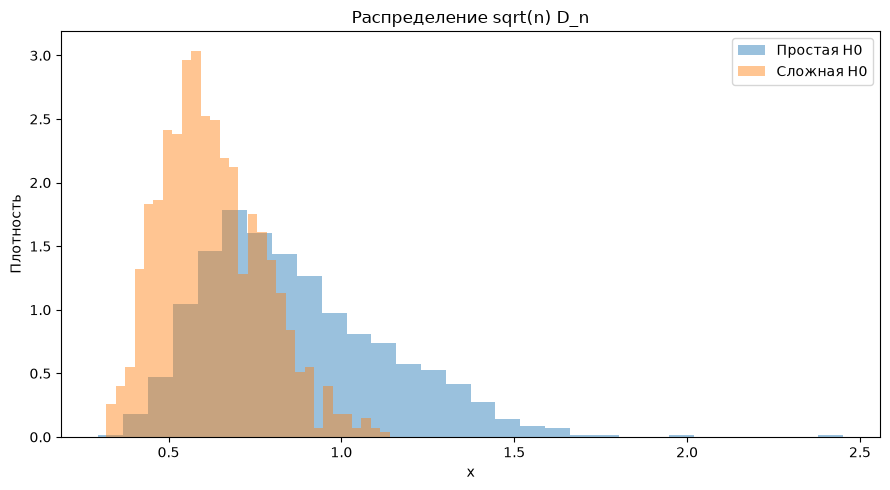

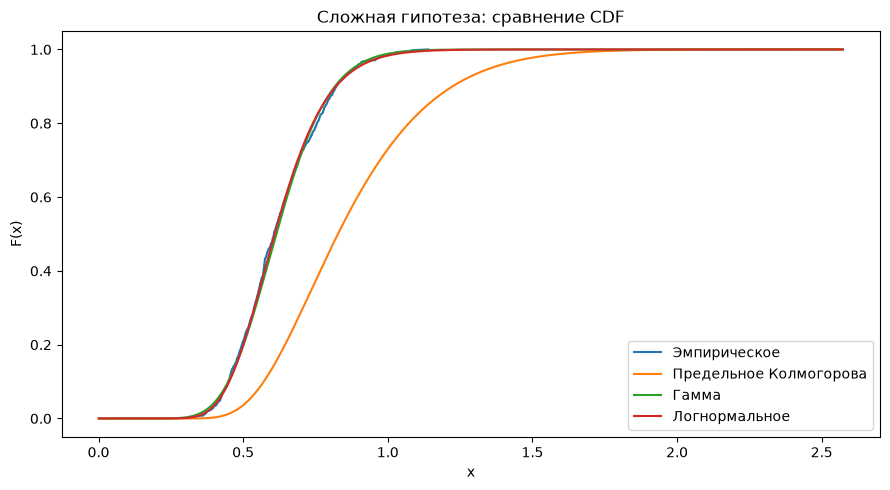

In [34]:
grid = np.linspace(
    0.001,
    max(K_complex.max(), K_simple.max()) * 1.05,
    500
)

plt.figure(figsize=(9, 5))
plt.hist(K_simple, bins=30, density=True,
         alpha=0.45, label="Простая H0")
plt.hist(K_complex, bins=30, density=True,
         alpha=0.45, label="Сложная H0")
plt.title("Распределение sqrt(n) D_n")
plt.xlabel("x")
plt.ylabel("Плотность")
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(9, 5))

x_sorted = np.sort(K_complex)
empirical_cdf = np.arange(1, N + 1) / N

plt.plot(x_sorted, empirical_cdf, label="Эмпирическое")
plt.plot(
    grid, kolmogorov_cdf(grid),
    label="Предельное Колмогорова"
)
plt.plot(
    grid,
    stats.gamma.cdf(
        grid, a=gamma_shape, loc=0, scale=gamma_scale
    ),
    label="Гамма"
)
plt.plot(
    grid,
    stats.lognorm.cdf(
        grid, s=lognorm_shape, loc=0, scale=lognorm_scale
    ),
    label="Логнормальное"
)

plt.title("Сложная гипотеза: сравнение CDF")
plt.xlabel("x")
plt.ylabel("F(x)")
plt.legend()
plt.tight_layout()
plt.show()